# 06. Q4 불만이 집중되는 판매자·카테고리·지역

- 단위: 리뷰가 있는 주문(주문당 대표 리뷰). 지연율만 배송 지표 대상 주문(`exclude_delivery_metrics = 0`) 기준
- **판매자 통제 가능 불만**: 분류된 리뷰에 WRONG_MISSING·DAMAGED·NOT_AS_DESCRIBED·LOW_QUALITY·SERVICE 중 하나라도 있는 주문
- **물류 불만**: NOT_RECEIVED·DELAY 중 하나라도 있는 주문
- 불만 비율의 분모는 전체 주문이다(분류되지 않은 4~5점·텍스트 없는 주문은 해당 불만 없음으로 봄)
- 판매자 분석은 **판매자가 1명인 주문만** 쓴다(여러 판매자 주문은 책임 판매자를 정할 수 없음)
- 쿼리: `sql/analysis/q4_*.sql` / 차트: `reports/figures/q4_*.png` / 결과 정리: `reports/analysis/q4_complaint_hotspots.md`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import beta as beta_dist
from scipy.stats import betabinom
from sqlalchemy import text
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint


def find_project_root(start: Path) -> Path:
    """sql/analysis 폴더가 있는 프로젝트 루트를 찾는다."""
    for path in [start, *start.parents]:
        if (path / "sql" / "analysis").is_dir():
            return path
    raise FileNotFoundError("프로젝트 루트를 찾지 못함")


ROOT = find_project_root(Path.cwd())
SQL_DIR = ROOT / "sql" / "analysis"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src" / "etl"))
from db import get_engine  # noqa: E402

engine = get_engine()

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

LABELS = ["NOT_RECEIVED", "WRONG_MISSING", "DAMAGED", "NOT_AS_DESCRIBED", "LOW_QUALITY", "SHIPPING_COST",
          "DELAY", "SERVICE", "OTHER", "UNCLEAR", "NO_COMPLAINT"]
LABEL_KO = {
    "NOT_RECEIVED": "미수령", "WRONG_MISSING": "오배송·누락", "DAMAGED": "파손·불량",
    "NOT_AS_DESCRIBED": "설명 불일치", "LOW_QUALITY": "품질 불만", "SHIPPING_COST": "배송비·수령 불편",
    "DELAY": "배송 지연", "SERVICE": "응대·환불", "OTHER": "기타", "UNCLEAR": "판단 불가", "NO_COMPLAINT": "불만 없음",
}
SELLER_TYPES = ["WRONG_MISSING", "DAMAGED", "NOT_AS_DESCRIBED", "LOW_QUALITY", "SERVICE"]
MIN_ORDERS = 30


def run_sql(name: str) -> pd.DataFrame:
    """sql/analysis의 SQL 파일을 실행해 DataFrame으로 돌려준다(DECIMAL은 float로)."""
    df = pd.read_sql(text((SQL_DIR / name).read_text(encoding="utf-8")), engine)
    for c in df.columns:
        if df[c].dtype == object and df[c].map(lambda v: hasattr(v, "as_tuple")).any():
            df[c] = df[c].astype(float)
    return df


def save(fig, name: str) -> None:
    """차트를 reports/figures에 저장한다."""
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    print(f"저장: reports/figures/{name}")

## 1. 판매자별 지표와 베이지안 보정

주문이 적은 판매자는 우연히 불만율이 0%나 50%가 되기 쉽다. **베타-이항 경험적 베이지안 보정**은 전체 판매자의 불만율 분포를 사전분포 Beta(α, β)로 추정하고(최대우도),
각 판매자의 불만율을 (불만 수 + α) / (주문 수 + α + β)로 바꾼다. 주문이 적을수록 전체 평균 쪽으로, 많을수록 자기 관측값 쪽으로 당겨진다.

In [2]:
sellers = run_sql("q4_01_seller_metrics.sql")
print(f"판매자 {len(sellers):,}명, 판매자 1명 주문 {int(sellers['n_orders'].sum()):,}건, 주문 {MIN_ORDERS}건 이상 판매자 {int((sellers['n_orders'] >= MIN_ORDERS).sum()):,}명")


def fit_beta_binomial(k: np.ndarray, n: np.ndarray) -> tuple[float, float]:
    """판매자별 (불만 수 k, 주문 수 n)로 베타-이항 사전분포 Beta(α, β)를 최대우도로 추정한다."""
    def nll(log_params):
        a, b = np.exp(log_params)
        return -betabinom.logpmf(k, n, a, b).sum()
    m = k.sum() / n.sum()
    res = minimize(nll, x0=np.log([m * 20, (1 - m) * 20]), method="Nelder-Mead", options={"maxiter": 2000, "xatol": 1e-6, "fatol": 1e-6})
    return tuple(np.exp(res.x))


priors = {}
for metric, k_col in [("seller_ctrl", "n_seller_ctrl"), ("low", "n_low")]:
    k, n = sellers[k_col].to_numpy(dtype=float), sellers["n_orders"].to_numpy(dtype=float)
    a, b = fit_beta_binomial(k, n)
    priors[metric] = (a, b)
    sellers[f"{metric}_raw"] = k / n
    sellers[f"{metric}_adj"] = (k + a) / (n + a + b)
    sellers[f"{metric}_adj_lo"] = beta_dist.ppf(0.05, k + a, n - k + b)  # 사후분포 90% 구간 하한
    print(f"{metric}: 사전분포 Beta(α={a:.2f}, β={b:.2f}), 사전 평균 {a / (a + b):.2%}, 사전 강도(α+β) {a + b:.1f}건 / 전체 비율 {k.sum() / n.sum():.2%}")

overall_ctrl = sellers["n_seller_ctrl"].sum() / sellers["n_orders"].sum()
big = sellers[sellers["n_orders"] >= MIN_ORDERS].copy()
summary = pd.DataFrame({
    "보정 전 표준편차": [sellers["seller_ctrl_raw"].std(), sellers["low_raw"].std()],
    "보정 후 표준편차": [sellers["seller_ctrl_adj"].std(), sellers["low_adj"].std()],
    "보정 전 최댓값": [sellers["seller_ctrl_raw"].max(), sellers["low_raw"].max()],
    "보정 후 최댓값": [sellers["seller_ctrl_adj"].max(), sellers["low_adj"].max()],
}, index=["판매자 통제 가능 불만율", "1~2점 비율"])
print("\n전체 판매자 기준 보정 전후 분포:")
display(summary.round(4))

판매자 3,073명, 판매자 1명 주문 96,653건, 주문 30건 이상 판매자 619명
seller_ctrl: 사전분포 Beta(α=2.88, β=33.16), 사전 평균 7.98%, 사전 강도(α+β) 36.0건 / 전체 비율 8.19%


low: 사전분포 Beta(α=3.61, β=22.05), 사전 평균 14.09%, 사전 강도(α+β) 25.7건 / 전체 비율 13.76%

전체 판매자 기준 보정 전후 분포:


,보정 전 표준편차,보정 후 표준편차,보정 전 최댓값,보정 후 최댓값
판매자 통제 가능 불만율,0.1715,0.0232,1.0,0.3910
1~2점 비율,0.2522,0.0377,1.0,0.5275


### 보정 전후 비교 산점도

대각선보다 아래에 있는 점은 보정으로 불만율이 내려간 판매자다. 점 크기와 색은 주문 수이며, 주문이 적은 판매자일수록 전체 평균 쪽으로 크게 당겨진다.

저장: reports/figures/q4_seller_shrinkage.png


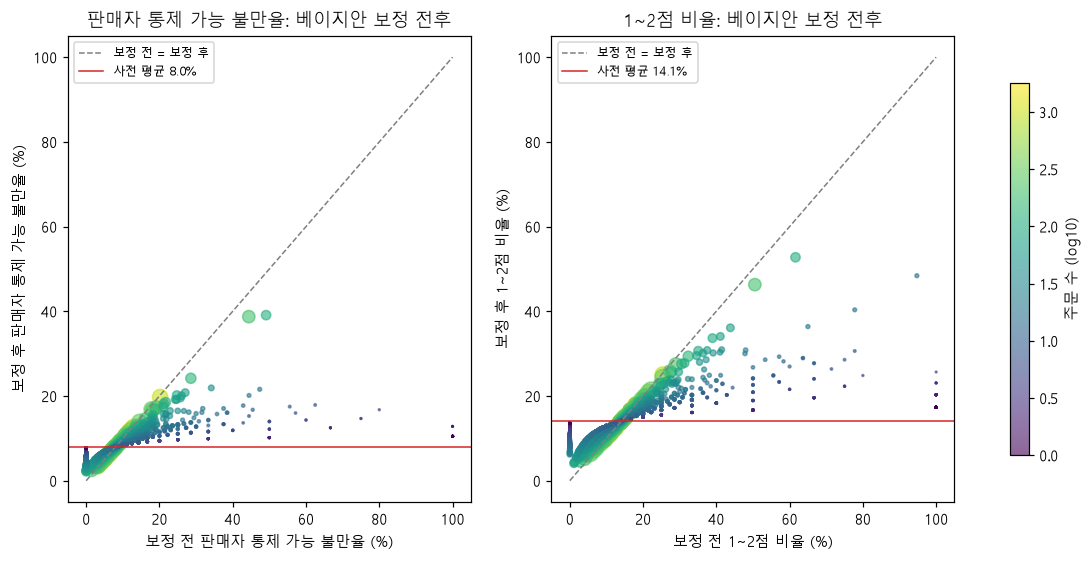

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, metric, title in [(axes[0], "seller_ctrl", "판매자 통제 가능 불만율"), (axes[1], "low", "1~2점 비율")]:
    sc = ax.scatter(sellers[f"{metric}_raw"] * 100, sellers[f"{metric}_adj"] * 100, s=np.clip(sellers["n_orders"], 3, 300) / 3,
                    c=np.log10(sellers["n_orders"]), cmap="viridis", alpha=0.6)
    lim = max(sellers[f"{metric}_raw"].max(), sellers[f"{metric}_adj"].max()) * 100
    ax.plot([0, lim], [0, lim], color="gray", linestyle="--", linewidth=1, label="보정 전 = 보정 후")
    a, b = priors[metric]
    ax.axhline(a / (a + b) * 100, color="#d62728", linewidth=1, label=f"사전 평균 {a / (a + b):.1%}")
    ax.set_xlabel(f"보정 전 {title} (%)")
    ax.set_ylabel(f"보정 후 {title} (%)")
    ax.set_title(f"{title}: 베이지안 보정 전후")
    ax.legend(fontsize=8, loc="upper left")
cbar = fig.colorbar(sc, ax=axes, shrink=0.8)
cbar.set_label("주문 수 (log10)")
save(fig, "q4_seller_shrinkage.png")
plt.show()

### 주문 30건 이상 판매자 순위 (보정 불만율 기준)

In [4]:
big = sellers[sellers["n_orders"] >= MIN_ORDERS].copy()
big["주요 불만 유형"] = big[[f"n_{t}" for t in SELLER_TYPES]].idxmax(axis=1).str[2:].map(LABEL_KO)
cols = ["seller_id", "seller_state", "n_orders", "n_seller_ctrl", "seller_ctrl_raw", "seller_ctrl_adj", "low_raw", "low_adj", "late_rate", "주요 불만 유형"]
print("보정 불만율 상위 10명:")
display(big.sort_values("seller_ctrl_adj", ascending=False)[cols].head(10).style.format(
    {"n_orders": "{:,.0f}", "n_seller_ctrl": "{:,.0f}", "seller_ctrl_raw": "{:.1%}", "seller_ctrl_adj": "{:.1%}",
     "low_raw": "{:.1%}", "low_adj": "{:.1%}", "late_rate": "{:.1%}"}))
print(f"보정 불만율과 보정 1~2점 비율의 상관(주문 {MIN_ORDERS}건 이상 판매자): {big['seller_ctrl_adj'].corr(big['low_adj']):.2f}")

보정 불만율 상위 10명:


,seller_id,seller_state,n_orders,n_seller_ctrl,seller_ctrl_raw,seller_ctrl_adj,low_raw,low_adj,late_rate,주요 불만 유형
183,1ca7077d890b907f89be8c954a02686a,SP,112,55,49.1%,39.1%,61.6%,52.7%,17.1%,설명 불일치
88,2eb70248d66e0e3ef83659f71b244378,SP,196,87,44.4%,38.7%,50.5%,46.3%,11.0%,설명 불일치
141,710e3548e02bc1d2831dfc4f1b5b14d4,PR,133,38,28.6%,24.2%,32.3%,29.4%,3.1%,오배송·누락
482,dc8798cbf453b7e0f98745e396cc5616,SP,41,14,34.1%,21.9%,41.5%,30.9%,5.7%,오배송·누락
286,a7f13822ceb966b076af67121f87b063,SP,74,20,27.0%,20.8%,29.7%,25.7%,4.2%,오배송·누락
209,8444e55c1f13cd5c179851e5ca5ebd00,MG,97,24,24.7%,20.2%,35.1%,30.7%,6.7%,오배송·누락
288,54965bbe3e4f07ae045b90b0b8541f52,PR,73,19,26.0%,20.1%,43.8%,36.1%,29.4%,응대·환불
10,7c67e1448b00f6e969d365cea6b010ab,SP,966,195,20.2%,19.7%,25.4%,25.1%,9.1%,오배송·누락
311,6fd52c528dcb38be2eea044946b811f8,SP,66,17,25.8%,19.5%,36.4%,30.1%,13.6%,품질 불만
271,712e6ed8aa4aa1fa65dab41fed5737e4,SC,78,19,24.4%,19.2%,34.6%,29.5%,19.7%,오배송·누락


보정 불만율과 보정 1~2점 비율의 상관(주문 30건 이상 판매자): 0.83


## 2. 불만 집중도: 로렌츠 곡선

판매자를 판매자 통제 가능 불만 건수가 많은 순으로 줄 세웠을 때, 상위 x% 판매자가 전체 불만의 몇 %를 차지하는지 본다.
불만이 많은 판매자는 주문도 많으므로 **주문 수의 집중도와 함께** 봐야 "불만이 특정 판매자에게 몰린다"는 결론을 낼 수 있다.

,상위 10% 판매자 비중,상위 20% 판매자 비중,지니 계수
판매자 통제 가능 불만 건수,0.741,0.879,0.848
주문 수,0.684,0.828,0.786


불만 건수 상위 10% 판매자 308명: 불만 74.1%, 주문 64.6%, 이들의 불만율 9.40% (전체 8.19%)
판매자 통제 가능 불만이 0건인 판매자: 55.1%


저장: reports/figures/q4_lorenz.png


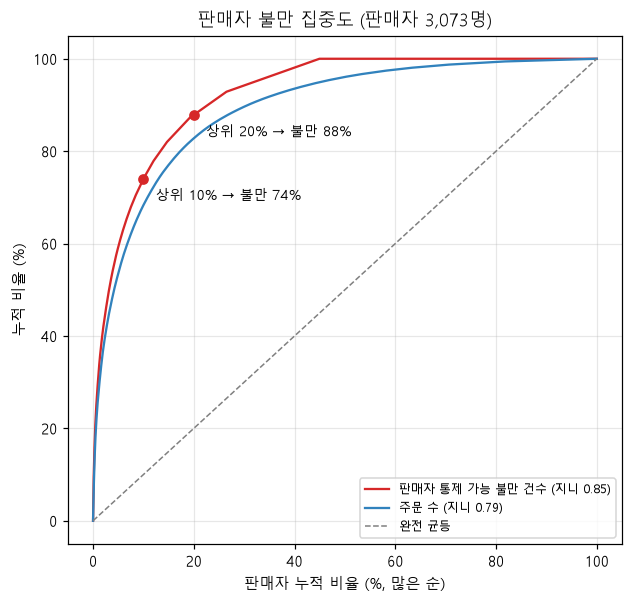

In [5]:
def lorenz(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """값이 큰 순으로 정렬한 누적 판매자 비율과 누적 값 비율(0에서 시작)."""
    v = np.sort(values)[::-1]
    return np.r_[0, np.arange(1, len(v) + 1) / len(v)], np.r_[0, np.cumsum(v) / v.sum()]


def top_share(values: np.ndarray, frac: float) -> float:
    """상위 frac 비율 판매자가 차지하는 값의 비율."""
    v = np.sort(values)[::-1]
    return v[: int(np.ceil(len(v) * frac))].sum() / v.sum()


def gini(values: np.ndarray) -> float:
    """지니 계수 (0: 완전 균등, 1: 한 명에게 집중)."""
    v = np.sort(values)
    n = len(v)
    return (2 * np.sum(np.arange(1, n + 1) * v) / (n * v.sum())) - (n + 1) / n


comp, orders = sellers["n_seller_ctrl"].to_numpy(float), sellers["n_orders"].to_numpy(float)
conc = pd.DataFrame({
    "상위 10% 판매자 비중": [top_share(comp, 0.1), top_share(orders, 0.1)],
    "상위 20% 판매자 비중": [top_share(comp, 0.2), top_share(orders, 0.2)],
    "지니 계수": [gini(comp), gini(orders)],
}, index=["판매자 통제 가능 불만 건수", "주문 수"])
display(conc.round(3))

# 주문 수 대비 불만 집중: 불만 상위 10% 판매자가 가진 주문 비중
order_by_comp = sellers.sort_values("n_seller_ctrl", ascending=False)
top10 = order_by_comp.head(int(np.ceil(len(sellers) * 0.1)))
print(f"불만 건수 상위 10% 판매자 {len(top10)}명: 불만 {top10['n_seller_ctrl'].sum() / comp.sum():.1%}, 주문 {top10['n_orders'].sum() / orders.sum():.1%}, "
      f"이들의 불만율 {top10['n_seller_ctrl'].sum() / top10['n_orders'].sum():.2%} (전체 {overall_ctrl:.2%})")
zero = (sellers["n_seller_ctrl"] == 0).mean()
print(f"판매자 통제 가능 불만이 0건인 판매자: {zero:.1%}")

fig, ax = plt.subplots(figsize=(6.5, 6))
for vals, label, color in [(comp, "판매자 통제 가능 불만 건수", "#d62728"), (orders, "주문 수", "#3182bd")]:
    x, y = lorenz(vals)
    ax.plot(x * 100, y * 100, label=f"{label} (지니 {gini(vals):.2f})", color=color)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, label="완전 균등")
for frac in (0.1, 0.2):
    s = top_share(comp, frac)
    ax.scatter([frac * 100], [s * 100], color="#d62728", zorder=3)
    ax.annotate(f"상위 {frac:.0%} → 불만 {s:.0%}", (frac * 100, s * 100), xytext=(8, -14), textcoords="offset points", fontsize=9)
ax.set_xlabel("판매자 누적 비율 (%, 많은 순)")
ax.set_ylabel("누적 비율 (%)")
ax.set_title(f"판매자 불만 집중도 (판매자 {len(sellers):,}명)")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3)
save(fig, "q4_lorenz.png")
plt.show()

## 3. 관리 대상 판매자

기준: 주문 30건 이상이고 **보정 불만율이 전체 평균의 1.5배 이상**인 판매자. 개선했을 때 줄일 수 있는 불만이 많은 순으로 보도록
**초과 불만 건수**(실제 불만 건수 − 주문 수 × 전체 평균 불만율)로 정렬한다.

In [6]:
watch = big[big["seller_ctrl_adj"] >= overall_ctrl * 1.5].copy()
watch["초과 불만 건수"] = watch["n_seller_ctrl"] - watch["n_orders"] * overall_ctrl
watch["주요 불만 유형 비중"] = watch[[f"n_{t}" for t in SELLER_TYPES]].max(axis=1) / watch["n_seller_ctrl"]
watch = watch.sort_values("초과 불만 건수", ascending=False)
print(f"관리 대상 판매자 {len(watch)}명 (전체 평균 {overall_ctrl:.2%}의 1.5배 = {overall_ctrl * 1.5:.2%} 이상): "
      f"불만 {int(watch['n_seller_ctrl'].sum()):,}건 = 판매자 통제 가능 불만 전체의 {watch['n_seller_ctrl'].sum() / comp.sum():.1%}, "
      f"초과 불만 {watch['초과 불만 건수'].sum():,.0f}건")
watch_cols = ["seller_id", "seller_state", "n_orders", "n_seller_ctrl", "초과 불만 건수", "seller_ctrl_raw", "seller_ctrl_adj",
              "low_adj", "late_rate", "주요 불만 유형", "주요 불만 유형 비중"]
display(watch[watch_cols].head(20).style.format(
    {"n_orders": "{:,.0f}", "n_seller_ctrl": "{:,.0f}", "초과 불만 건수": "{:,.1f}", "seller_ctrl_raw": "{:.1%}",
     "seller_ctrl_adj": "{:.1%}", "low_adj": "{:.1%}", "late_rate": "{:.1%}", "주요 불만 유형 비중": "{:.0%}"}))
print("관리 대상 판매자의 주요 불만 유형 분포:", watch["주요 불만 유형"].value_counts().to_dict())

관리 대상 판매자 60명 (전체 평균 8.19%의 1.5배 = 12.29% 이상): 불만 1,351건 = 판매자 통제 가능 불만 전체의 17.1%, 초과 불만 778건


,seller_id,seller_state,n_orders,n_seller_ctrl,초과 불만 건수,seller_ctrl_raw,seller_ctrl_adj,low_adj,late_rate,주요 불만 유형,주요 불만 유형 비중
10,7c67e1448b00f6e969d365cea6b010ab,SP,966,195,115.9,20.2%,19.7%,25.1%,9.1%,오배송·누락,50%
88,2eb70248d66e0e3ef83659f71b244378,SP,196,87,70.9,44.4%,38.7%,46.3%,11.0%,설명 불일치,37%
183,1ca7077d890b907f89be8c954a02686a,SP,112,55,45.8,49.1%,39.1%,52.7%,17.1%,설명 불일치,76%
12,1025f0e2d44d7041d6cf58b6550e0bfa,SP,877,113,41.2,12.9%,12.7%,16.5%,8.1%,오배송·누락,74%
51,897060da8b9a21f655304d50fd935913,SP,308,55,29.8,17.9%,16.8%,24.5%,9.8%,설명 불일치,45%
141,710e3548e02bc1d2831dfc4f1b5b14d4,PR,133,38,27.1,28.6%,24.2%,29.4%,3.1%,오배송·누락,66%
68,88460e8ebdecbfecb5f9601833981930,PR,228,41,22.3,18.0%,16.6%,27.4%,18.1%,파손·불량,39%
79,7040e82f899a04d1b434b795a43b4617,SP,205,39,22.2,19.0%,17.4%,25.8%,8.0%,파손·불량,51%
47,5dceca129747e92ff8ef7a997dc4f8ca,SP,316,46,20.1,14.6%,13.9%,19.2%,5.8%,오배송·누락,80%
169,229c3efbfb0ea2058de4ccdfbc3d784a,MG,120,26,16.2,21.7%,18.5%,23.1%,1.7%,설명 불일치,62%


관리 대상 판매자의 주요 불만 유형 분포: {'오배송·누락': 20, '설명 불일치': 14, '응대·환불': 12, '품질 불만': 9, '파손·불량': 5}


## 4. 카테고리별 불만 유형

주문 300건 이상 카테고리. 히트맵 값은 **lift = 카테고리의 유형 비율 / 전체 유형 비율**(분류된 리뷰 기준)이다. 1.5 이상이면 그 카테고리에서 해당 불만이 두드러지게 많다는 뜻이다.
분류된 리뷰가 적은 카테고리는 비율이 흔들리므로, "두드러진 유형" 표는 lift 1.5 이상이면서 해당 유형 리뷰가 15건 이상인 경우만 뽑는다.

,category,n_orders,low_rate,late_rate,n_classified
1,bed_bath_table,"9,313",16.8%,7.3%,"1,628"
2,health_beauty,"8,771",12.7%,7.4%,"1,086"
3,sports_leisure,"7,669",13.0%,6.5%,985
4,computers_accessories,"6,649",16.1%,6.3%,"1,071"
5,furniture_decor,"6,398",16.7%,7.0%,"1,038"
6,housewares,"5,843",13.2%,5.3%,812
7,watches_gifts,"5,576",15.2%,7.2%,890
8,telephony,"4,168",15.5%,7.0%,671
9,auto,"3,877",14.5%,7.2%,566
10,toys,"3,853",12.7%,6.2%,461


전체 대비 두드러지게 높은 불만 유형 (lift ≥ 1.5, 해당 리뷰 15건 이상):


,카테고리,유형,카테고리 비율,전체 비율,lift,해당 리뷰 수
16,furniture_living_room,파손·불량,27.3%,10.3%,2.65,18
11,office_furniture,파손·불량,22.5%,10.3%,2.18,72
18,audio,파손·불량,22.2%,10.3%,2.16,16
8,fashion_bags_accessories,배송비·수령 불편,7.0%,3.3%,2.13,15
13,home_appliances,설명 불일치,21.0%,9.9%,2.13,21
0,bed_bath_table,품질 불만,18.3%,8.6%,2.13,298
17,home_confort,품질 불만,17.4%,8.6%,2.02,16
9,(미분류),설명 불일치,18.0%,9.9%,1.83,47
14,home_construction,오배송·누락,40.2%,23.0%,1.75,35
3,watches_gifts,기타,4.8%,2.8%,1.74,43


저장: reports/figures/q4_category_heatmap.png


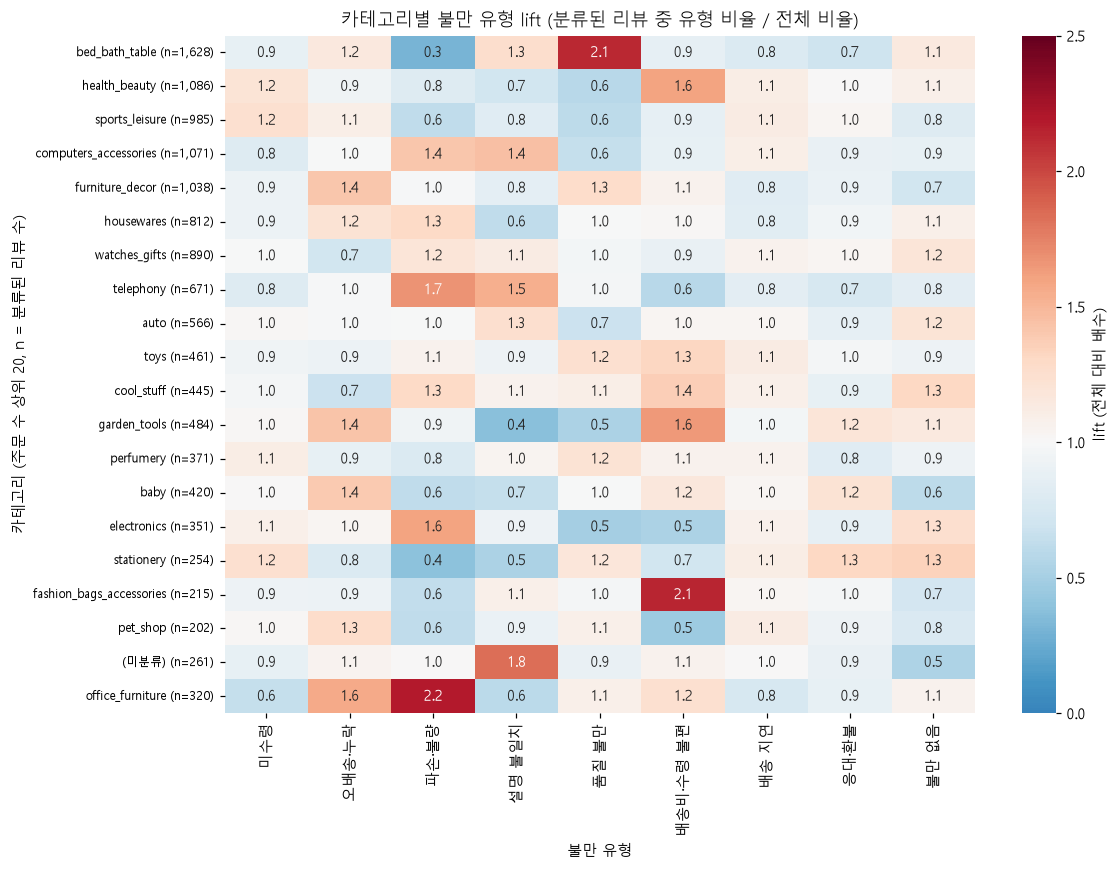

In [7]:
cat = run_sql("q4_02_category_metrics.sql")
overall_row = cat[cat["category"] == "(전체)"].iloc[0]
cats = cat[cat["category"] != "(전체)"].copy()
lift = cats.set_index("category")[LABELS].div(overall_row[LABELS].astype(float))
display(cats[["category", "n_orders", "low_rate", "late_rate", "n_classified"]].style.format(
    {"n_orders": "{:,.0f}", "low_rate": "{:.1%}", "late_rate": "{:.1%}", "n_classified": "{:,.0f}"}))

rows = []
for _, r in cats.iterrows():
    for t in LABELS:
        cnt = r[t] * r["n_classified"]
        if t != "NO_COMPLAINT" and lift.loc[r["category"], t] >= 1.5 and cnt >= 15:
            rows.append({"카테고리": r["category"], "유형": LABEL_KO[t], "카테고리 비율": r[t], "전체 비율": overall_row[t],
                         "lift": lift.loc[r["category"], t], "해당 리뷰 수": int(round(cnt))})
standout = pd.DataFrame(rows).sort_values("lift", ascending=False)
print("전체 대비 두드러지게 높은 불만 유형 (lift ≥ 1.5, 해당 리뷰 15건 이상):")
display(standout.style.format({"카테고리 비율": "{:.1%}", "전체 비율": "{:.1%}", "lift": "{:.2f}"}))

heat_types = [t for t in LABELS if t not in ("UNCLEAR", "OTHER")]
heat = lift.loc[cats.sort_values("n_orders", ascending=False)["category"].head(20), heat_types].astype(float)
heat.columns = [LABEL_KO[t] for t in heat_types]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdBu_r", center=1, vmin=0, vmax=2.5, cbar_kws={"label": "lift (전체 대비 배수)"}, ax=ax)
ax.set_yticklabels([f"{c} (n={int(cats.set_index('category').loc[c, 'n_classified']):,})" for c in heat.index], fontsize=8)
ax.set_xlabel("불만 유형")
ax.set_ylabel("카테고리 (주문 수 상위 20, n = 분류된 리뷰 수)")
ax.set_title("카테고리별 불만 유형 lift (분류된 리뷰 중 유형 비율 / 전체 비율)")
save(fig, "q4_category_heatmap.png")
plt.show()

## 5. 지역별 지표

고객 주(주문 300건 이상)별 지연율과 물류 불만 비율, 판매자 주별 지연율과 판매자 통제 가능 불만 비율.

,customer_state,n_orders,low_rate,n_delivery_base,late_rate,logistics_rate
19,AL,410,23.9%,394,20.8%,13.2%
14,MA,742,21.8%,712,17.1%,10.2%
20,SE,349,21.8%,334,15.0%,9.2%
17,PI,490,18.4%,471,13.8%,5.7%
11,CE,"1,326",19.7%,"1,273",13.7%,10.0%
1,RJ,"12,687",20.7%,"12,210",11.9%,8.8%
6,BA,"3,340",18.9%,"3,229",11.9%,8.0%
12,PA,962,19.5%,933,10.7%,8.5%
9,ES,"2,006",15.0%,"1,969",10.4%,5.7%
16,PB,530,16.6%,512,10.2%,8.7%


고객 주별 지연율과 물류 불만 비율의 상관(주문 300건 이상 21개 주): 0.90


,seller_state,n_orders,n_sellers,low_rate,late_rate,seller_ctrl_rate
0,SP,"68,513",1838,14.3%,7.3%,8.5%
1,MG,"7,698",241,11.7%,4.7%,7.2%
2,PR,"7,410",345,13.0%,5.4%,7.6%
3,RJ,"4,225",170,13.4%,7.1%,7.5%
4,SC,"3,551",190,12.7%,4.9%,7.3%
5,RS,"1,934",126,9.3%,3.1%,6.2%
6,DF,815,30,15.1%,5.3%,9.7%
7,BA,562,19,12.8%,4.8%,8.9%
8,GO,457,40,9.6%,2.9%,6.6%
9,PE,400,9,10.8%,3.5%,6.0%


저장: reports/figures/q4_customer_state.png


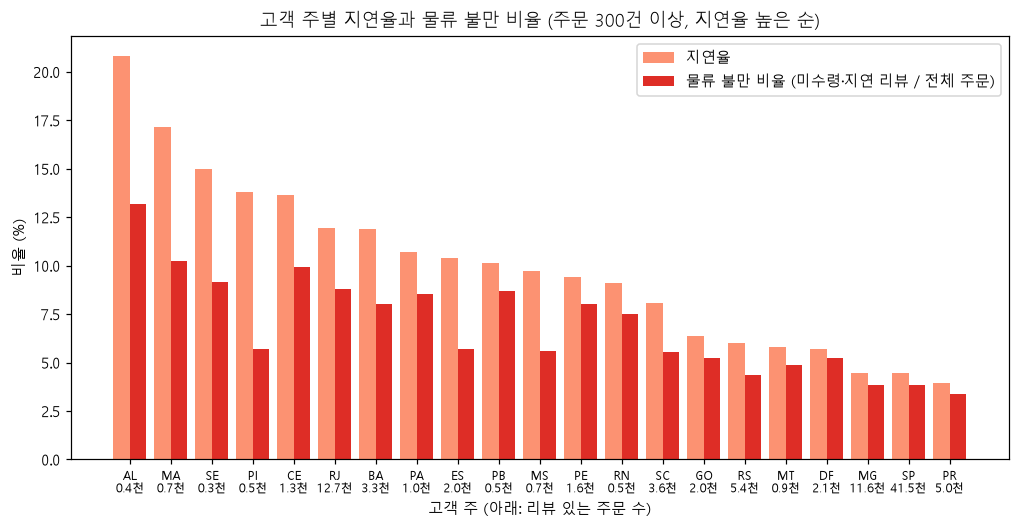

In [8]:
cust_state = run_sql("q4_03_customer_state.sql")
cs = cust_state[cust_state["n_orders"] >= 300].sort_values("late_rate", ascending=False)
display(cs.style.format({"n_orders": "{:,.0f}", "low_rate": "{:.1%}", "n_delivery_base": "{:,.0f}", "late_rate": "{:.1%}", "logistics_rate": "{:.1%}"}))
print(f"고객 주별 지연율과 물류 불만 비율의 상관(주문 300건 이상 {len(cs)}개 주): {cs['late_rate'].corr(cs['logistics_rate']):.2f}")

seller_state = run_sql("q4_04_seller_state.sql")
display(seller_state[seller_state["n_orders"] >= 300].style.format(
    {"n_orders": "{:,.0f}", "low_rate": "{:.1%}", "late_rate": "{:.1%}", "seller_ctrl_rate": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(cs))
ax.bar(x - 0.2, cs["late_rate"] * 100, width=0.4, label="지연율", color="#fc9272")
ax.bar(x + 0.2, cs["logistics_rate"] * 100, width=0.4, label="물류 불만 비율 (미수령·지연 리뷰 / 전체 주문)", color="#de2d26")
ax.set_xticks(x, [f"{s}\n{n / 1000:.1f}천" for s, n in zip(cs["customer_state"], cs["n_orders"])], fontsize=8)
ax.set_ylabel("비율 (%)")
ax.set_xlabel("고객 주 (아래: 리뷰 있는 주문 수)")
ax.set_title("고객 주별 지연율과 물류 불만 비율 (주문 300건 이상, 지연율 높은 순)")
ax.legend()
save(fig, "q4_customer_state.png")
plt.show()

## 6. 여러 판매자 주문 가설 (Q2 발견 5번 검증)

Q2 회귀에서 판매자 수가 1명 늘 때 1~2점 오즈비가 4.6이었다. 그 원인이 "판매자가 여러 명"인지, "상품이 여러 개"인지 구분하려고
**판매자 1명·상품 2개 이상** 주문을 비교군으로 둔다.

In [9]:
ms = run_sql("q4_05_multi_seller.sql").set_index("grp")
ms["1~2점 비율"] = ms["n_low"] / ms["n_orders"]
ms["지연율"] = ms["n_late"] / ms["n_delivery_base"]
for t in ["WRONG_MISSING", "NOT_RECEIVED", "DELAY", "DAMAGED", "NOT_AS_DESCRIBED", "LOW_QUALITY", "SERVICE"]:
    ms[f"{LABEL_KO[t]} (전체 주문 대비)"] = ms[f"n_{t}"] / ms["n_orders"]
    ms[f"{LABEL_KO[t]} (분류 리뷰 중)"] = ms[f"n_{t}"] / ms["n_classified"]
display(ms[["n_orders", "n_classified", "1~2점 비율", "지연율", "오배송·누락 (전체 주문 대비)", "미수령 (전체 주문 대비)",
            "오배송·누락 (분류 리뷰 중)", "미수령 (분류 리뷰 중)", "배송 지연 (분류 리뷰 중)"]].T.style.format("{:.3f}"))


def diff_ci(k1, n1, k0, n0):
    """비율 차이(%p)와 Newcombe 95% 신뢰구간, 비율의 비와 95% 신뢰구간."""
    lo, hi = confint_proportions_2indep(k1, n1, k0, n0, method="newcomb", compare="diff")
    rlo, rhi = confint_proportions_2indep(k1, n1, k0, n0, method="log", compare="ratio")
    return (k1 / n1 - k0 / n0) * 100, lo * 100, hi * 100, (k1 / n1) / (k0 / n0), rlo, rhi


comparisons = []
pairs = [("판매자 2명 이상", "판매자 1명·상품 1개"), ("판매자 1명·상품 2개 이상", "판매자 1명·상품 1개"), ("판매자 2명 이상", "판매자 1명·상품 2개 이상")]
for g1, g0 in pairs:
    for name, k_col, n_col in [("1~2점 비율", "n_low", "n_orders"), ("오배송·누락 (전체 주문 대비)", "n_WRONG_MISSING", "n_orders"),
                               ("지연율", "n_late", "n_delivery_base")]:
        d, lo, hi, rr, rlo, rhi = diff_ci(int(ms.loc[g1, k_col]), int(ms.loc[g1, n_col]), int(ms.loc[g0, k_col]), int(ms.loc[g0, n_col]))
        comparisons.append({"비교": f"{g1} vs {g0}", "지표": name, "그룹1": ms.loc[g1, k_col] / ms.loc[g1, n_col],
                            "그룹0": ms.loc[g0, k_col] / ms.loc[g0, n_col], "차이(%p)": d, "CI 하한(%p)": lo, "CI 상한(%p)": hi,
                            "비율의 비": rr, "비 CI 하한": rlo, "비 CI 상한": rhi})
comp_df = pd.DataFrame(comparisons)
display(comp_df.style.format({"그룹1": "{:.1%}", "그룹0": "{:.1%}", "차이(%p)": "{:+.1f}", "CI 하한(%p)": "{:+.1f}", "CI 상한(%p)": "{:+.1f}",
                              "비율의 비": "{:.2f}", "비 CI 하한": "{:.2f}", "비 CI 상한": "{:.2f}"}))

grp,판매자 1명·상품 1개,판매자 1명·상품 2개 이상,판매자 2명 이상
n_orders,88227.000,8426.000,1264.000
n_classified,11127.000,2152.000,619.000
1~2점 비율,0.127,0.247,0.474
지연율,0.068,0.058,0.010
오배송·누락 (전체 주문 대비),0.016,0.160,0.375
미수령 (전체 주문 대비),0.034,0.037,0.089
오배송·누락 (분류 리뷰 중),0.130,0.628,0.766
미수령 (분류 리뷰 중),0.269,0.143,0.181
배송 지연 (분류 리뷰 중),0.240,0.126,0.066


,비교,지표,그룹1,그룹0,차이(%p),CI 하한(%p),CI 상한(%p),비율의 비,비 CI 하한,비 CI 상한
0,판매자 2명 이상 vs 판매자 1명·상품 1개,1~2점 비율,47.4%,12.7%,+34.7,+31.9,+37.4,3.73,3.51,3.96
1,판매자 2명 이상 vs 판매자 1명·상품 1개,오배송·누락 (전체 주문 대비),37.5%,1.6%,+35.9,+33.2,+38.6,22.85,20.93,24.94
2,판매자 2명 이상 vs 판매자 1명·상품 1개,지연율,1.0%,6.8%,-5.9,-6.3,-5.1,0.14,0.08,0.25
3,판매자 1명·상품 2개 이상 vs 판매자 1명·상품 1개,1~2점 비율,24.7%,12.7%,+12.0,+11.1,+13.0,1.95,1.87,2.03
4,판매자 1명·상품 2개 이상 vs 판매자 1명·상품 1개,오배송·누락 (전체 주문 대비),16.0%,1.6%,+14.4,+13.6,+15.2,9.78,9.11,10.49
5,판매자 1명·상품 2개 이상 vs 판매자 1명·상품 1개,지연율,5.8%,6.8%,-1.0,-1.5,-0.5,0.85,0.78,0.93
6,판매자 2명 이상 vs 판매자 1명·상품 2개 이상,1~2점 비율,47.4%,24.7%,+22.7,+19.8,+25.6,1.92,1.79,2.05
7,판매자 2명 이상 vs 판매자 1명·상품 2개 이상,오배송·누락 (전체 주문 대비),37.5%,16.0%,+21.5,+18.7,+24.3,2.34,2.14,2.55
8,판매자 2명 이상 vs 판매자 1명·상품 2개 이상,지연율,1.0%,5.8%,-4.8,-5.5,-4.0,0.17,0.09,0.29


저장: reports/figures/q4_multi_seller_types.png


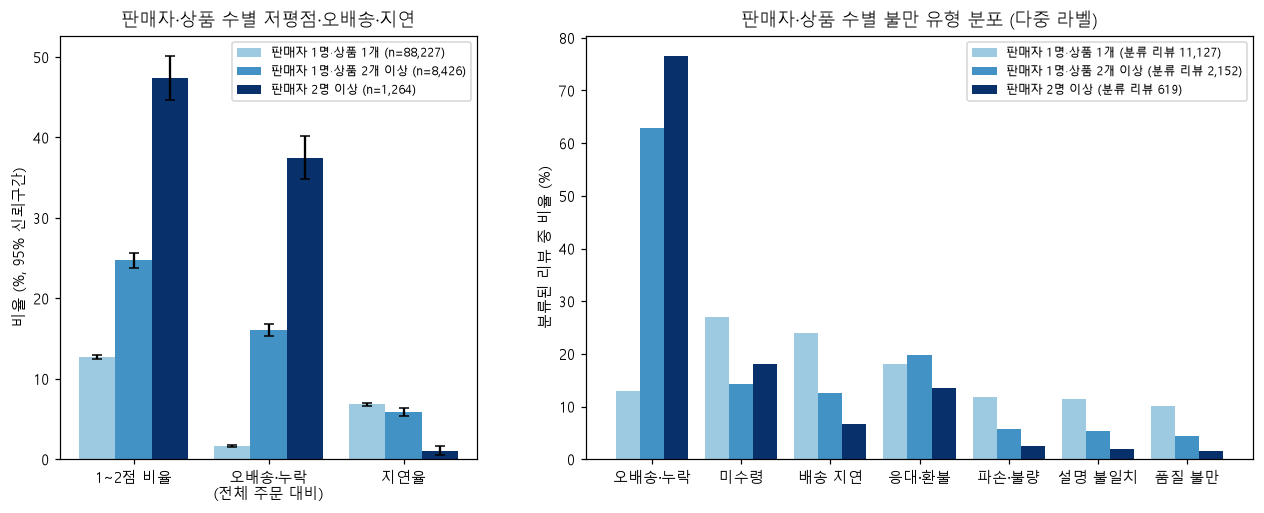

In [10]:
groups = list(ms.index)
colors = ["#9ecae1", "#4292c6", "#08306b"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
metrics = [("1~2점 비율", "n_low", "n_orders"), ("오배송·누락\n(전체 주문 대비)", "n_WRONG_MISSING", "n_orders"), ("지연율", "n_late", "n_delivery_base")]
x = np.arange(len(metrics))
for i, g in enumerate(groups):
    vals, errs = [], [[], []]
    for _, k_col, n_col in metrics:
        k, n = int(ms.loc[g, k_col]), int(ms.loc[g, n_col])
        lo, hi = proportion_confint(k, n, method="wilson")
        vals.append(k / n * 100); errs[0].append((k / n - lo) * 100); errs[1].append((hi - k / n) * 100)
    ax.bar(x + (i - 1) * 0.27, vals, width=0.27, yerr=errs, capsize=3, color=colors[i], label=f"{g} (n={int(ms.loc[g, 'n_orders']):,})")
ax.set_xticks(x, [m[0] for m in metrics])
ax.set_ylabel("비율 (%, 95% 신뢰구간)")
ax.set_title("판매자·상품 수별 저평점·오배송·지연")
ax.legend(fontsize=8)

ax = axes[1]
types = ["WRONG_MISSING", "NOT_RECEIVED", "DELAY", "SERVICE", "DAMAGED", "NOT_AS_DESCRIBED", "LOW_QUALITY"]
x = np.arange(len(types))
for i, g in enumerate(groups):
    ax.bar(x + (i - 1) * 0.27, [ms.loc[g, f"n_{t}"] / ms.loc[g, "n_classified"] * 100 for t in types], width=0.27, color=colors[i],
           label=f"{g} (분류 리뷰 {int(ms.loc[g, 'n_classified']):,})")
ax.set_xticks(x, [LABEL_KO[t] for t in types])
ax.set_ylabel("분류된 리뷰 중 비율 (%)")
ax.set_title("판매자·상품 수별 불만 유형 분포 (다중 라벨)")
ax.legend(fontsize=8)
save(fig, "q4_multi_seller_types.png")
plt.show()

## 정리

핵심 발견, 관리 대상 판매자 상위 10명, 가설 검증 결과, 해석 주의점은 `reports/analysis/q4_complaint_hotspots.md`에 정리했다.